# 1. Dataset introduction

This notebook explores the **InfraredSolarModules** dataset for our ENGG2112 solar-panel fault classification project. We want to predict one of **12 labels** from a thermal module image: 11 anomaly categories and `No-Anomaly`. These labels describe observed conditions; a prediction is not a panel safety or reuse certification.

Source: [Raptor Maps / InfraredSolarModules](https://github.com/RaptorMaps/InfraredSolarModules). The source archive contains 20,000 grayscale images, each **24 pixels wide × 40 pixels tall**. Its MIT license is retained with the local download.

We explore **training images only** for image examples and brightness statistics. Counts across partitions are bookkeeping checks. Duplicate examples below are restricted to excluded images or retained training images. We do not train a model, tune on test images, or change the frozen split.

**Before running:** install `requirements.txt` in your Python environment and select that environment as the notebook kernel. Download/extract the dataset into `data/raw/`, then run `scripts/audit_data.py`, `scripts/review_near_duplicates.py`, and `scripts/create_split.py --verify-only` from the repository root (see `data/README.md`). Run the cells in order. Paths work from the repository root or its `notebooks/` folder.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/pv_fault/data.py").is_file():
    raise RuntimeError("Open this notebook from the repository root or notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
from pv_fault.data import CLASS_NAMES, SolarModuleDataset

DATA = ROOT / "data"
CLEAN = DATA / "processed/near_clean"
MANIFEST = DATA / "splits/infrared_solar_modules_v1.csv"
required = [DATA / "raw/module_metadata.json", CLEAN / "module_metadata.json",
            DATA / "processed/exclusions.csv", DATA / "processed/near_duplicate_candidates.csv",
            CLEAN / "exclusions.csv", CLEAN / "related_groups.csv", MANIFEST]
missing = [str(path.relative_to(ROOT)) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Run the download/cleaning setup first. Missing: " + ", ".join(missing))

# Read-only verification of fingerprints, groups, labels and every image's bytes.
verification = subprocess.run([sys.executable, str(ROOT / "scripts/create_split.py"),
                               "--verify-only"], cwd=ROOT, capture_output=True, text=True)
if verification.returncode:
    raise RuntimeError(verification.stdout + verification.stderr)
print(verification.stdout)
manifest = pd.read_csv(MANIFEST, dtype=str)
raw_metadata = json.loads((DATA / "raw/module_metadata.json").read_text())
exact_metadata = json.loads((DATA / "processed/module_metadata.json").read_text())
clean_metadata = json.loads((CLEAN / "module_metadata.json").read_text())
train = manifest.loc[manifest["split"].eq("train")].reset_index(drop=True)
train_dataset = SolarModuleDataset("train", data_root=DATA, manifest=MANIFEST)
assert [row["image_id"] for row in train_dataset.rows] == train["image_id"].tolist()
SEED = 2112
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(CLASS_NAMES)} classes; {len(train_dataset):,} training images")


Manifest, groups, metadata, and all image bytes verified.
Class                 train    val   test
Cell                  1310    280    280
Cell-Multi             898    193    193
Cracking               655    141    141
Diode                 1043    223    223
Diode-Multi            123     26     26
Hot-Spot               174     37     37
Hot-Spot-Multi         172     37     37
No-Anomaly            6980   1496   1496
Offline-Module         572    123    123
Shadowing              731    156    156
Soiling                142     31     31
Vegetation            1146    245    245
TOTAL                13946   2988   2988
Keep the test assignments unchanged and use validation for model selection.



12 classes; 13,946 training images


## 2. Example images

Three reproducibly selected **training images per class** help us see the visual variation within a label. All panels use a fixed brightness scale from 0 to 1 and nearest-neighbour enlargement: no smoothing or invented detail. The class names come from the supplied annotations, not independent expert verification.


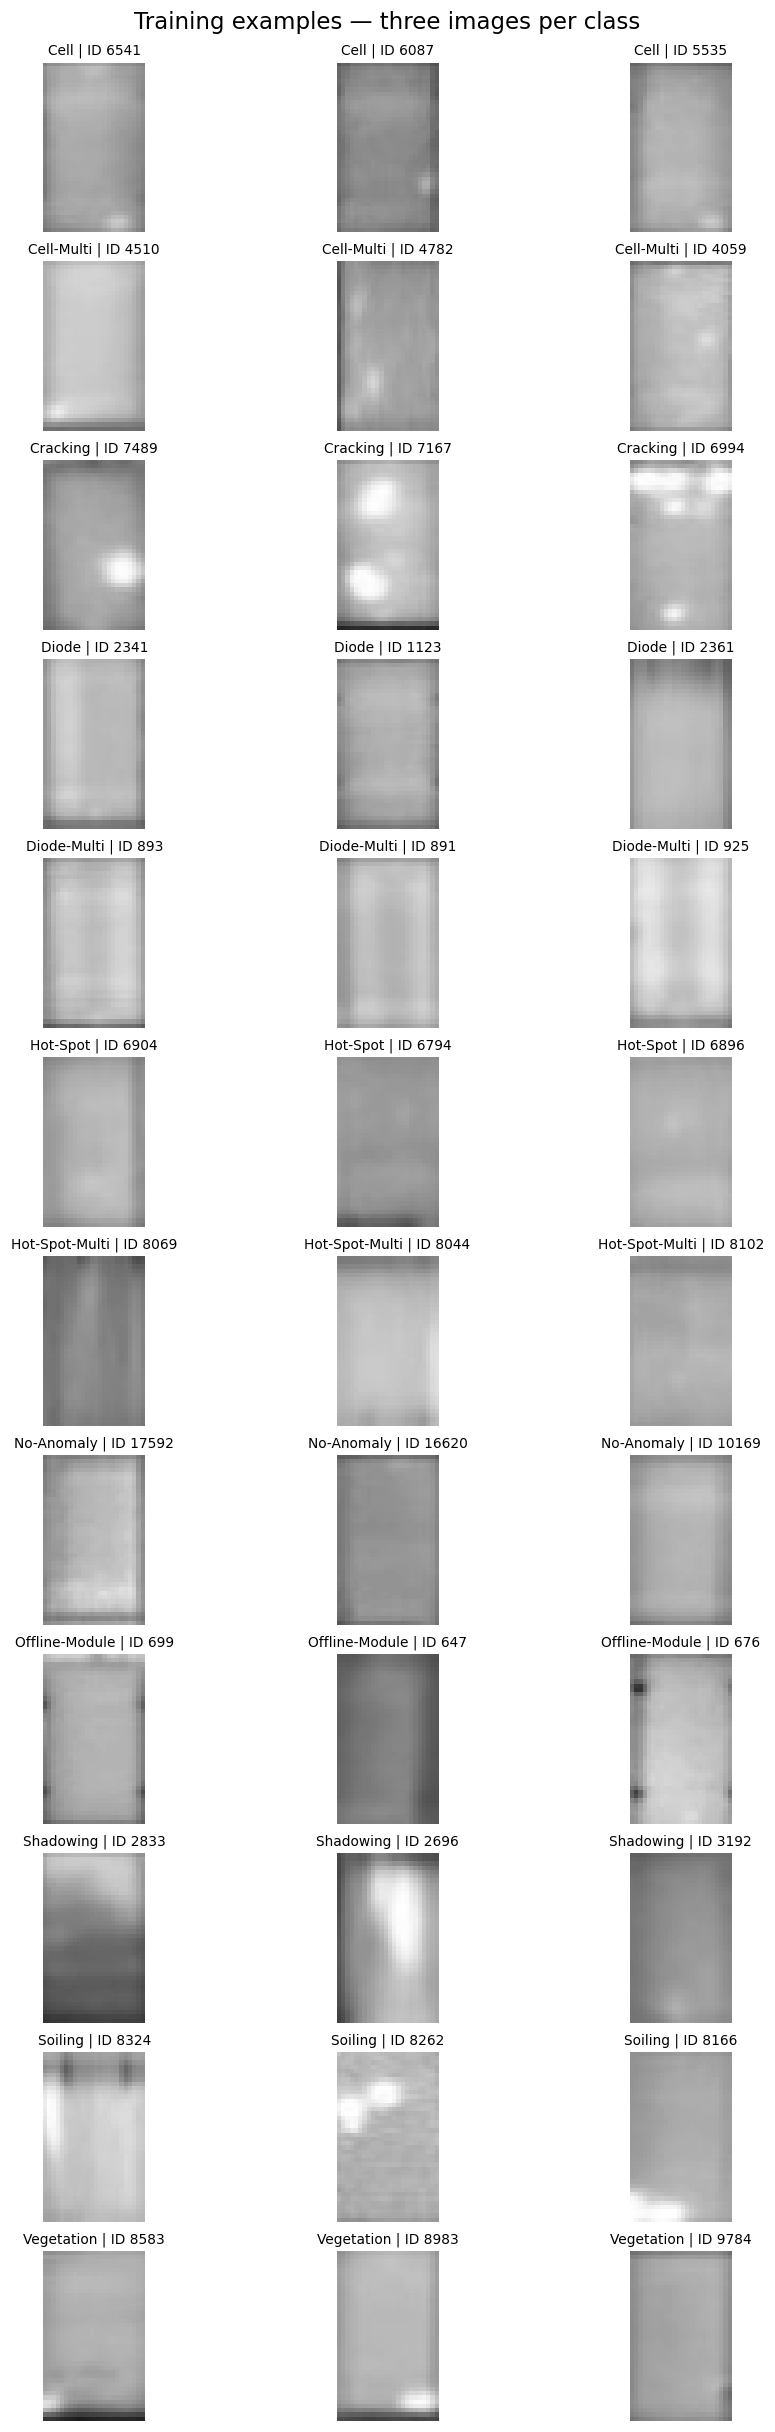

In [2]:
fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(8, 22), layout="constrained")
for row_number, label in enumerate(CLASS_NAMES):
    selected = train.loc[train["label"].eq(label)].sample(n=3, random_state=SEED)
    for ax, index in zip(axes[row_number], selected.index):
        image, target = train_dataset[int(index)]
        assert CLASS_NAMES[target] == label
        ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{label} | ID {train.loc[index, 'image_id']}", fontsize=9)
        ax.axis("off")
fig.suptitle("Training examples — three images per class", fontsize=15)
plt.show()


## 3. Class distribution

The table compares source and retained counts. The chart uses training counts, because these are the examples the model learns from. A classifier that always says `No-Anomaly` can have high accuracy while detecting no faults. Macro-F1 and per-class recall will therefore matter alongside accuracy.


,raw,retained,train,excluded
Cell,1877,1870,1310,7
Cell-Multi,1288,1284,898,4
Cracking,940,937,655,3
Diode,1499,1489,1043,10
Diode-Multi,175,175,123,0
Hot-Spot,249,248,174,1
Hot-Spot-Multi,246,246,172,0
No-Anomaly,10000,9972,6980,28
Offline-Module,827,818,572,9
Shadowing,1056,1043,731,13


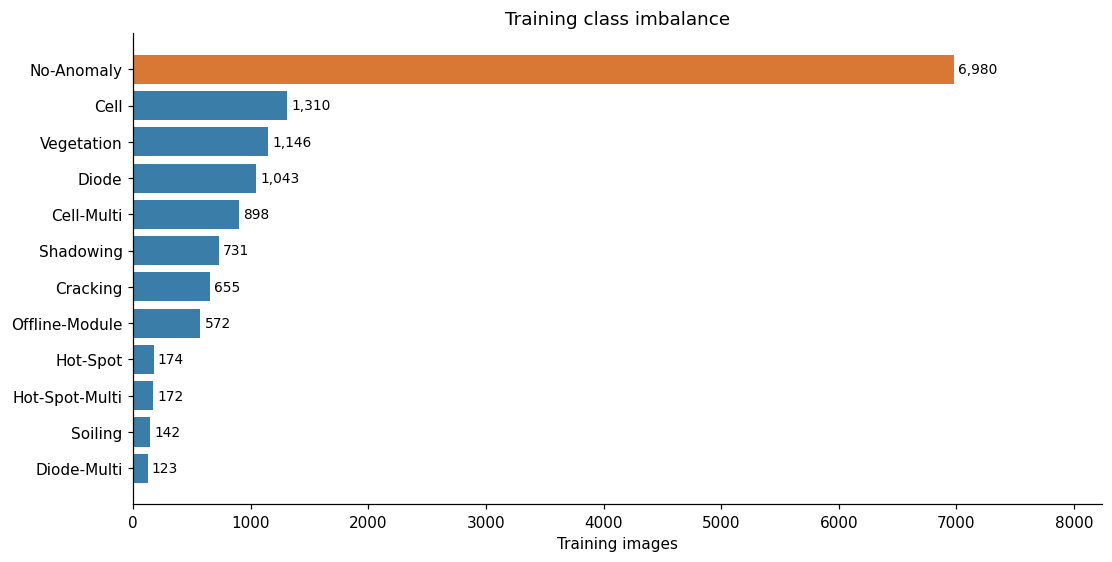

**Always predicting No-Anomaly gives 50.1% training accuracy**, but zero recall for every fault class. The largest class has **56.7×** as many training examples as the smallest.

In [3]:
raw_counts = pd.Series(Counter(item["anomaly_class"] for item in raw_metadata.values()))
counts = pd.DataFrame({
    "raw": raw_counts,
    "retained": manifest["label"].value_counts(),
    "train": train["label"].value_counts(),
}).reindex(CLASS_NAMES).astype(int)
counts["excluded"] = counts["raw"] - counts["retained"]
display(counts)
ordered = counts["train"].sort_values()
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.barh(ordered.index, ordered.values, color=["#d97835" if label == "No-Anomaly" else "#397da8" for label in ordered.index])
ax.set(xlabel="Training images", title="Training class imbalance")
for i, value in enumerate(ordered):
    ax.text(value + 35, i, f"{value:,}", va="center", fontsize=9)
ax.set_xlim(0, ordered.max() * 1.18)
plt.show()
normal_share = counts.loc["No-Anomaly", "train"] / len(train)
ratio = counts["train"].max() / counts["train"].min()
display(Markdown(f"**Always predicting No-Anomaly gives {normal_share:.1%} training accuracy**, but zero recall for every fault class. The largest class has **{ratio:.1f}×** as many training examples as the smallest."))


## 4. Image properties and model inputs

We check dimensions/mode and summarise every **training image**. The loader returns `[1, 40, 24]`: one grayscale channel, 40 rows and 24 columns. Each integer pixel is divided by 255, preserving relative brightness while expressing it between 0 and 1. This is a fixed unit conversion, not temperature calibration or per-image contrast stretching.

Image intensity is not a calibrated temperature. Differences in average brightness can reflect acquisition or rendering as well as panel conditions; these plots alone cannot establish physical causes.


,,,training_images
width,height,mode,
24,40,L,13946


**Brightness summary for 13,946 training images**

,Average across images,Median image value,Middle 50% of image values,Lowest to highest image value
Measurement,,,,
Average brightness in an image,0.620,0.647,0.548 to 0.711,0.042 to 0.974
Brightness variation within an image,0.075,0.071,0.052 to 0.093,0.006 to 0.292
Darkest pixel in an image,0.359,0.361,0.263 to 0.459,0.000 to 0.839
Brightest pixel in an image,0.770,0.780,0.682 to 0.890,0.075 to 1.000


**How to read this:** first calculate each measurement separately for each image, then summarise those image measurements across the training set. For average brightness, 0 means black and 1 means white. Brightness variation is the standard deviation of pixels **within one image**: a low value means fairly uniform brightness; a higher value means more variation. The median has half the image values below it and half above. The middle 50% column runs from the 25th to the 75th percentile.

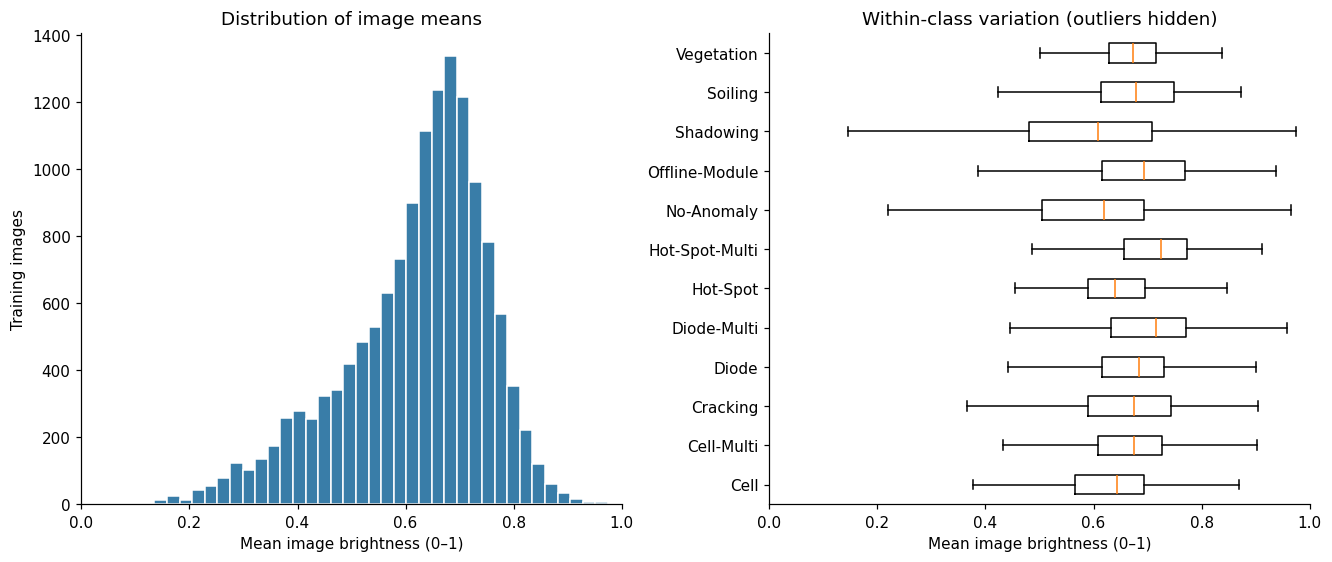

In [4]:
properties = []
for index, row in train.iterrows():
    with Image.open(DATA / "raw" / row["image_path"]) as image:
        width, height = image.size
        mode = image.mode
    tensor, target = train_dataset[int(index)]
    pixels = tensor.numpy()
    properties.append({"image_id": row["image_id"], "label": row["label"],
                       "width": width, "height": height, "mode": mode,
                       "mean": float(pixels.mean()), "std": float(pixels.std()),
                       "minimum": float(pixels.min()), "maximum": float(pixels.max())})
properties = pd.DataFrame(properties)
display(properties.groupby(["width", "height", "mode"]).size().rename("training_images").to_frame())
# Each row is a measurement within one image; columns summarise all images.
measurement_names = {
    "mean": "Average brightness in an image",
    "std": "Brightness variation within an image",
    "minimum": "Darkest pixel in an image",
    "maximum": "Brightest pixel in an image",
}
summary_rows = []
for column, description in measurement_names.items():
    values = properties[column]
    summary_rows.append({
        "Measurement": description,
        "Average across images": f"{values.mean():.3f}",
        "Median image value": f"{values.median():.3f}",
        "Middle 50% of image values": f"{values.quantile(0.25):.3f} to {values.quantile(0.75):.3f}",
        "Lowest to highest image value": f"{values.min():.3f} to {values.max():.3f}",
    })
display(Markdown(f"**Brightness summary for {len(properties):,} training images**"))
display(pd.DataFrame(summary_rows).set_index("Measurement"))
display(Markdown(
    "**How to read this:** first calculate each measurement separately for each image, "
    "then summarise those image measurements across the training set. "
    "For average brightness, 0 means black and 1 means white. "
    "Brightness variation is the standard deviation of pixels **within one image**: "
    "a low value means fairly uniform brightness; a higher value means more variation. "
    "The median has half the image values below it and half above. "
    "The middle 50% column runs from the 25th to the 75th percentile."
))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
axes[0].hist(properties["mean"], bins=40, color="#397da8", edgecolor="white")
axes[0].set(xlabel="Mean image brightness (0–1)", ylabel="Training images", title="Distribution of image means", xlim=(0, 1))
axes[1].boxplot([properties.loc[properties["label"].eq(label), "mean"].values for label in CLASS_NAMES],
                vert=False, tick_labels=CLASS_NAMES, showfliers=False)
axes[1].set(xlabel="Mean image brightness (0–1)", title="Within-class variation (outliers hidden)", xlim=(0, 1))
plt.show()


## 5. Cleaning summary

Exact matching compares decoded pixels. Matching-label duplicates keep one representative; conflicting exact-label groups are excluded entirely. Near-duplicate screening uses a difference hash with distance at most one bit, plus an 8×8 thumbnail mean absolute difference of at most four brightness levels.

**Near-duplicate candidates are not confirmed annotation errors.** The current rule excludes every image involved in a different-label candidate pair. This may remove legitimate examples; manual review is deferred. Same-label candidates are retained and grouped for splitting. Source images remain untouched. Changing these rules later requires a new dataset/split version.


,stage,images
0,Original,20000
1,After exact cleaning,19972
2,After near-duplicate filtering,19922


,images_excluded
reason,
conflicting_labels,12
exact_duplicate,16
cross_label_near_duplicate_candidate,50


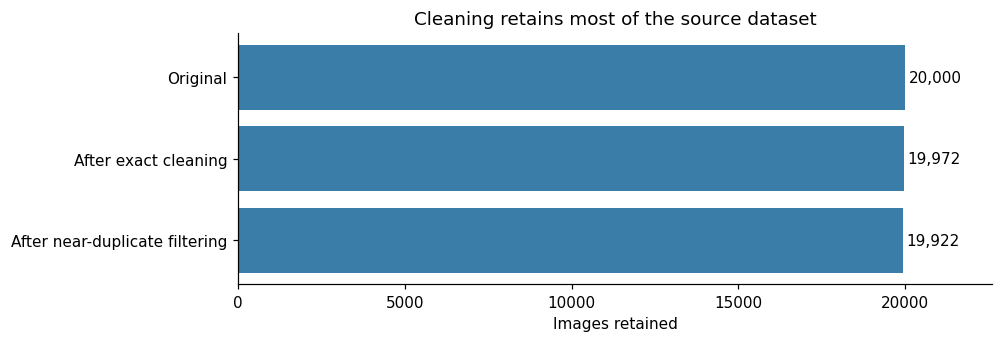

In [5]:
exact_exclusions = pd.read_csv(DATA / "processed/exclusions.csv", dtype=str)
near_exclusions = pd.read_csv(CLEAN / "exclusions.csv", dtype=str)
candidates = pd.read_csv(DATA / "processed/near_duplicate_candidates.csv", dtype={"first_id": str, "second_id": str})
stages = pd.DataFrame({"stage": ["Original", "After exact cleaning", "After near-duplicate filtering"],
                       "images": [len(raw_metadata), len(exact_metadata), len(clean_metadata)]})
display(stages)
reasons = exact_exclusions.groupby("reason").size().rename("images_excluded").to_frame()
reasons.loc["cross_label_near_duplicate_candidate"] = len(near_exclusions)
display(reasons)
assert len(raw_metadata) - len(exact_exclusions) == len(exact_metadata)
assert len(exact_metadata) - len(near_exclusions) == len(clean_metadata) == len(manifest)
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.barh(stages["stage"][::-1], stages["images"][::-1], color="#397da8")
ax.set(xlabel="Images retained", title="Cleaning retains most of the source dataset", xlim=(0, len(raw_metadata) * 1.13))
for i, value in enumerate(stages["images"][::-1]):
    ax.text(value + 100, i, f"{value:,}", va="center")
plt.show()


## 6. Duplicate examples

The following pairs illustrate the cleaning rules, not a manual relabelling decision. To avoid inspecting validation/test images, we show a pair only when each image is either **excluded from the retained dataset** or **assigned to training**. As a result, these examples are selected for illustration and are not representative estimates of duplicate frequency.


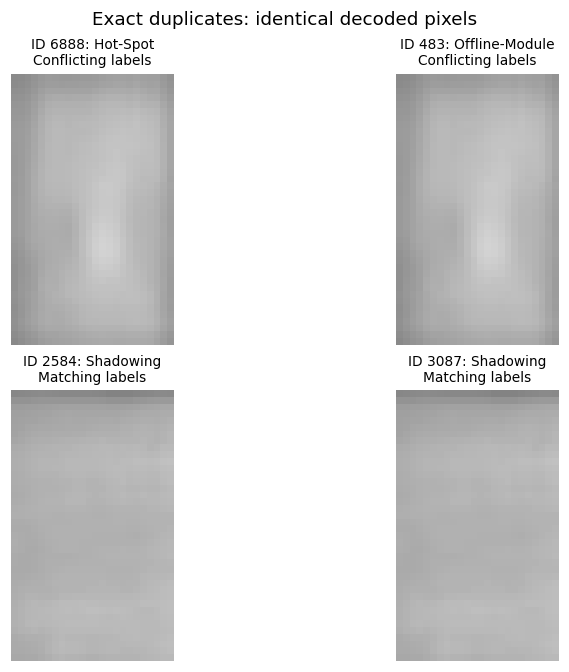

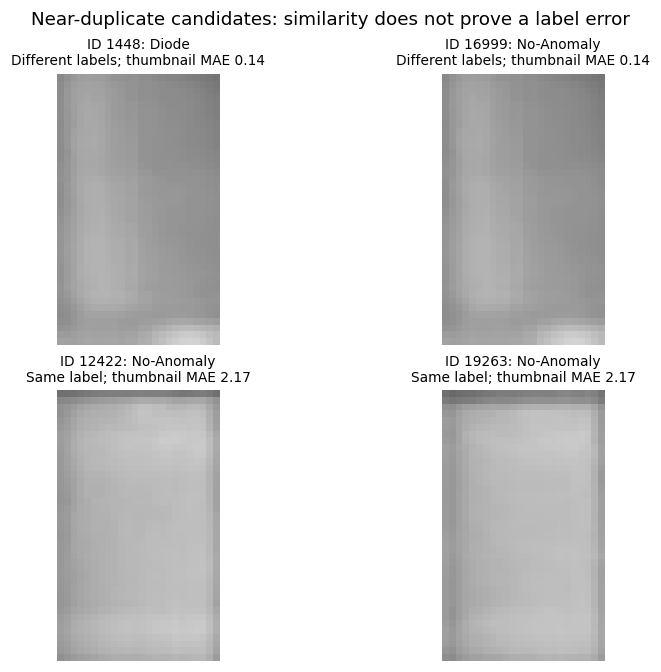

In [6]:
train_ids = set(train["image_id"])
retained_ids = set(manifest["image_id"])
def safe_to_show(image_id):
    return image_id not in retained_ids or image_id in train_ids

def show_pairs(pairs, title):
    if not pairs:
        display(Markdown(f"{title}: no eligible pairs without opening held-out images."))
        return
    fig, axes = plt.subplots(len(pairs), 2, figsize=(7, 3 * len(pairs)), squeeze=False, layout="constrained")
    for row_axes, (first, second, note) in zip(axes, pairs):
        for ax, image_id in zip(row_axes, (first, second)):
            assert safe_to_show(image_id)
            details = raw_metadata[image_id]
            with Image.open(DATA / "raw" / details["image_filepath"]) as image:
                ax.imshow(np.asarray(image), cmap="gray", vmin=0, vmax=255, interpolation="nearest")
            ax.set_title(f"ID {image_id}: {details['anomaly_class']}\n{note}", fontsize=9)
            ax.axis("off")
    fig.suptitle(title)
    plt.show()

exact_groups = pd.read_csv(DATA / "processed/duplicate_groups.csv", dtype=str)
exact_pairs = []
for _, group in exact_groups.groupby("group_number", sort=False):
    ids = group["image_id"].tolist()
    if len(ids) >= 2 and all(safe_to_show(i) for i in ids):
        note = "Conflicting labels" if group["label"].nunique() > 1 else "Matching labels"
        if not any(pair[2] == note for pair in exact_pairs):
            exact_pairs.append((ids[0], ids[1], note))
show_pairs(exact_pairs, "Exact duplicates: identical decoded pixels")
near_pairs = []
for _, pair in candidates.iterrows():
    first, second = pair["first_id"], pair["second_id"]
    kind = "Different labels" if pair["first_label"] != pair["second_label"] else "Same label"
    if safe_to_show(first) and safe_to_show(second) and not any(p[2].startswith(kind) for p in near_pairs):
        near_pairs.append((first, second, f"{kind}; thumbnail MAE {pair['thumbnail_mae']:.2f}"))
show_pairs(near_pairs, "Near-duplicate candidates: similarity does not prove a label error")


## 7. Frozen split and leakage checks

The target proportions are 70% training, 15% validation and 15% test, approximately stratified by class. Related-image groups stay in one partition. The manifest seed is 2112. Never regenerate these assignments during model selection.

Group separation controls detected visual duplicates. There are no verified panel, site or capture identifiers, and the near-duplicate screen is incomplete. These checks therefore **do not establish performance on unseen sites or panels**.


split,train,val,test
label,,,
Cell,1310,280,280
Cell-Multi,898,193,193
Cracking,655,141,141
Diode,1043,223,223
Diode-Multi,123,26,26
Hot-Spot,174,37,37
Hot-Spot-Multi,172,37,37
No-Anomaly,6980,1496,1496
Offline-Module,572,123,123


,images
split,
train,13946
val,2988
test,2988


Verified 19,922 unique images in 19,741 groups.
No recorded related-image group crosses partitions; every class appears in every split.


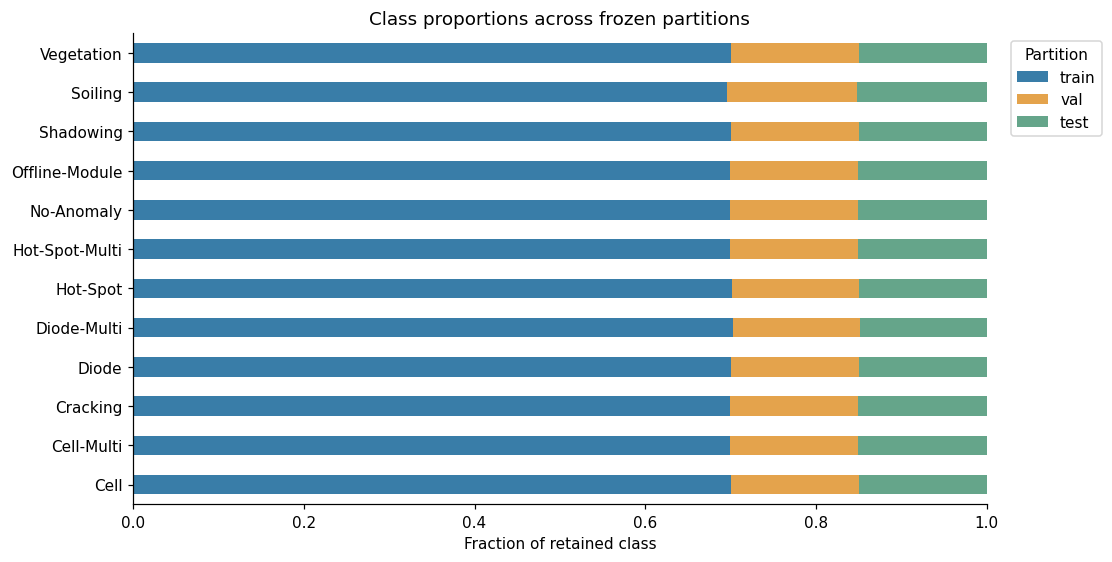

In [7]:
split_counts = pd.crosstab(manifest["label"], manifest["split"]).reindex(index=CLASS_NAMES, columns=["train", "val", "test"])
display(split_counts)
display(manifest["split"].value_counts().reindex(["train", "val", "test"]).rename("images").to_frame())
assert manifest["image_id"].is_unique
assert manifest.groupby("group_id")["split"].nunique().eq(1).all()
assert split_counts.gt(0).all().all()
summary = json.loads(MANIFEST.with_suffix(".json").read_text())
assert hashlib.sha256(MANIFEST.read_bytes()).hexdigest() == summary["manifest_sha256"]
print(f"Verified {manifest['image_id'].nunique():,} unique images in {manifest['group_id'].nunique():,} groups.")
print("No recorded related-image group crosses partitions; every class appears in every split.")
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
fractions = split_counts.div(split_counts.sum(axis=1), axis=0)
fractions.plot.barh(stacked=True, ax=ax, color=["#397da8", "#e4a34c", "#65a58a"])
ax.set(xlabel="Fraction of retained class", ylabel="", xlim=(0, 1), title="Class proportions across frozen partitions")
ax.legend(title="Partition", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


## 8. Takeaways and next steps

- **Small, single-channel inputs:** 40×24 pixels limit visible detail. Begin with the existing small CNN and keep preprocessing explicit.
- **Substantial imbalance:** about half the images are `No-Anomaly`. Compare macro-F1, per-class recall and faults predicted as normal, not accuracy alone. Any loss weighting should be calculated from training labels only.
- **Auditable preparation:** 78 images are excluded under the current rules. Exact conflicts and visually similar cross-label candidates have different levels of certainty; revisit the candidate exclusions through documented review.
- **A fixed benchmark:** group-aware partitions reduce detected duplicate leakage, but cannot demonstrate generalisation to unseen sites.
- **Brightness has limits:** scaled intensity is not temperature, and visual similarity is not proof of identical physical conditions.

Continue to `02_baseline_experiments.ipynb` for the implemented CNN training and comparisons. Use validation for model selection and early stopping, consider label-preserving augmentation on training images only, and reserve final test evaluation until the model and settings are chosen. This notebook has not fitted a model or measured predictive performance.
